# Tarea 2: Modelo de regresión para predecir profundida de sismos
*Por: Lucas Pierry y Constanza Padilla*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## Visualización y ajuste de datos

In [2]:
terremotos = pd.read_csv(r"C:\Users\Usuario\OneDrive\Escritorio\Universidad\Semestre X\Machine Learning\AST332\Tareas\earthquakes_usgs.csv")
terremotos.head()

,Unnamed: 0,time,latitude,longitude,depth,mag,magType,place,type,status,net,nst,rms
0,0,1900-01-05T19:00:00.000Z,-3.0,102.0,NaN,7.0,ms,"Southern Sumatra, Indonesia",earthquake,reviewed,cent,NaN,NaN
1,1,1900-01-11T09:07:00.000Z,-5.0,148.0,NaN,7.0,ms,Bismarck Sea,earthquake,reviewed,cent,NaN,NaN
2,2,1900-01-20T06:33:00.000Z,20.0,-105.0,NaN,7.3,mw,"Jalisco, Mexico",earthquake,reviewed,cent,NaN,NaN
3,3,1900-01-31T19:22:00.000Z,48.0,146.0,450.0,7.5,mj,Sea of Okhotsk,earthquake,reviewed,cent,NaN,NaN
4,4,1900-04-30T22:41:14.000Z,36.9,-121.6,NaN,4.5,ml,"Near Aromas, California",earthquake,reviewed,ushis,NaN,NaN


In [3]:
terremotos.shape

(310535, 13)

Intentaremos predecir la profundidad de un sismo (target) a partir de 4 variables (features): magnitud, latitud, longitud y año de registro. Esto puede ser útil, ya que en diversos registros sismográficos, la profunidad del evento es desconocida, al no haber sido registrada en el momento.

Como en principio nos interesa solo el año (no todo el detalle de fecha y hora que aparece en el registro), hacemos una modificación para conservar solo los primeros 4 caracteres de la columna 'time'.
Además, 'depth' contiene datos NaN, que en una primera instancia reemplazaremos por 0 para entrenar el primer modelo.
Nos preocupamos también de conservar solo los sismos naturales, que son los que competen a este análisis.

In [4]:
terremotos["time"] = terremotos["time"].str[:4]
terremotos["depth"] = terremotos["depth"].fillna(0)
terremotos = terremotos[terremotos["type"] == 'earthquake']

In [5]:
terremotos.head()

,Unnamed: 0,time,latitude,longitude,depth,mag,magType,place,type,status,net,nst,rms
0,0,1900,-3.0,102.0,0.0,7.0,ms,"Southern Sumatra, Indonesia",earthquake,reviewed,cent,NaN,NaN
1,1,1900,-5.0,148.0,0.0,7.0,ms,Bismarck Sea,earthquake,reviewed,cent,NaN,NaN
2,2,1900,20.0,-105.0,0.0,7.3,mw,"Jalisco, Mexico",earthquake,reviewed,cent,NaN,NaN
3,3,1900,48.0,146.0,450.0,7.5,mj,Sea of Okhotsk,earthquake,reviewed,cent,NaN,NaN
4,4,1900,36.9,-121.6,0.0,4.5,ml,"Near Aromas, California",earthquake,reviewed,ushis,NaN,NaN


In [6]:
terremotos.shape

(309821, 13)

## Modelo Benchmark

In [7]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

Definimos las características a usar:

In [8]:
features = ['mag', 'longitude', 'latitude', 'time']

Ahora el target:

In [9]:
target = 'depth'

In [10]:
X = terremotos[features]
y = terremotos[target]

Implementaremos un modelo de RandomForest.

In [11]:
model = RandomForestRegressor(n_jobs=-1)

In [12]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Comenzamos definiendo un Benchmark para usar de referencia y luego mejorar el modelo. Usamos R² como métrica principal porque cuantifica qué proporción de la variabilidad de la profundidad explica el modelo respecto de un baseline que predice la media. Además, al no tener unidades, permite comparar entrenamiento, test y el experimento. Como R² puede verse favorecido por la alta varianza de la profundidad (pocos sismos muy profundos), lo complementamos más adelante con MAE, que da el error típico en km, y RMSE, que penaliza más los errores grandes. Implementamos el modelo en esquema de validación cruzada.

In [13]:
%%time
cv = KFold(shuffle=True, n_splits=5, random_state=5)
scores = cross_validate(model, X, y, cv=cv, scoring='r2')

CPU times: total: 10min 40s
Wall time: 1min 4s


In [14]:
scores

{'fit_time': array([27.45445061,  8.24237537,  9.09818554,  9.1269114 ,  8.83306837]),
 'score_time': array([0.28712869, 0.28700161, 0.26977682, 0.25644064, 0.25825739]),
 'test_score': array([0.89195633, 0.89167912, 0.89439909, 0.89433272, 0.89144152])}

In [15]:
r2_prom = np.mean(scores['test_score'])
r2_std = np.std(scores['test_score'])

In [16]:
r2_prom, r2_std

(np.float64(0.8927617553651104), np.float64(0.0013200465616781032))

Vemos que el primer Benchmark ya es bastante bueno, con un $R^2$ promedio de $\sim 0.89$, y una desviación estándar de 0.003 entre folds. Tenemos bias relativamente bajo, y también varianza baja. Esto es bastante alentador, pues aún hay ajustes por hacer que probablemente permitan mejorar el score.

Visualicemos en un gráfico los resultados.

In [17]:
ypred = cross_val_predict(model, X, y, cv=cv)

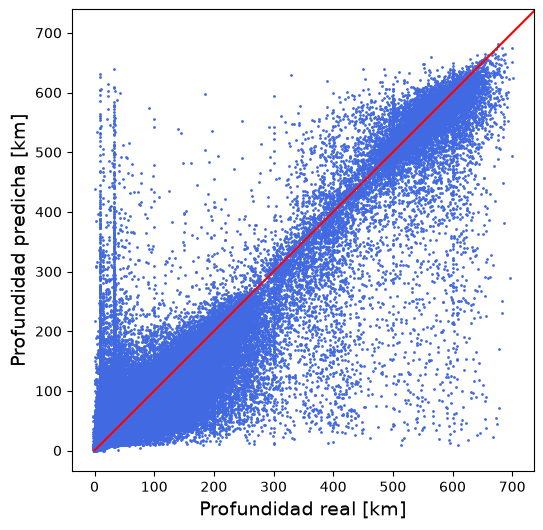

In [24]:
plt.figure(figsize=(10,6))
plt.scatter(y, ypred, s = 1, c = 'royalblue')
plt.xlabel('Profundidad real [km]', fontsize=14)
plt.ylabel('Profundidad predicha [km]',fontsize=14)
plt.axis('square')
plt.plot([0,800], [0, 800], color='red')
plt.show()


Al visualizar las predicciones, salta de inmediato a la vista que el panorama no es tan bueno como parece solo viendo las métricas. Sin embargo, aún se puede ir optimizando el modelo.

### Eliminación de valores NaN

Es evidente que reemplazar los valores de 'depth' desconocidos (NaN) por ceros, introduce mucho error en el entrenamiento del modelo. Por ello, conviene no considerar los eventos para los cuales no se tiene una profundidad conocida.

Como reemplazamos los NaN por ceros, ahora eliminaremos del registro las filas cuyo 'depth' sea igual a 0. Esto lo podemos hacer sin estar eliminando información real porque sabemos que ningún sismo natural puede producirse a profundidad 0.

In [20]:
terremotos2 = terremotos[terremotos["depth"] != 0]

In [21]:
print(terremotos2["depth"].isna().sum())
print(terremotos2.shape)

0
(308960, 13)


Nos quedan un poco mas de 1000 registros al eliminar los sismos de profundidad NaN.

In [22]:
X2 = terremotos2[features]
y2 = terremotos2[target]

In [23]:
%%time
cv = KFold(shuffle=True, n_splits=5, random_state=5)
scores = cross_validate(model, X2, y2, cv=cv, scoring='r2')

CPU times: total: 10min 27s
Wall time: 45.5 s


In [25]:
scores

{'fit_time': array([8.48130512, 8.71027613, 8.67783999, 8.813761  , 9.13199115]),
 'score_time': array([0.27173042, 0.25930858, 0.27271152, 0.27149057, 0.27496243]),
 'test_score': array([0.89355649, 0.89486735, 0.89257185, 0.88833714, 0.89297654])}

In [28]:
r2_prom = np.mean(scores['test_score'])
r2_std = np.std(scores['test_score'])

In [ ]:
r2_prom, r2_std

(np.float64(0.8924618753976862), np.float64(0.0022034009751641347))

In [26]:
ypred2 = cross_val_predict(model, X2, y2, cv=cv)

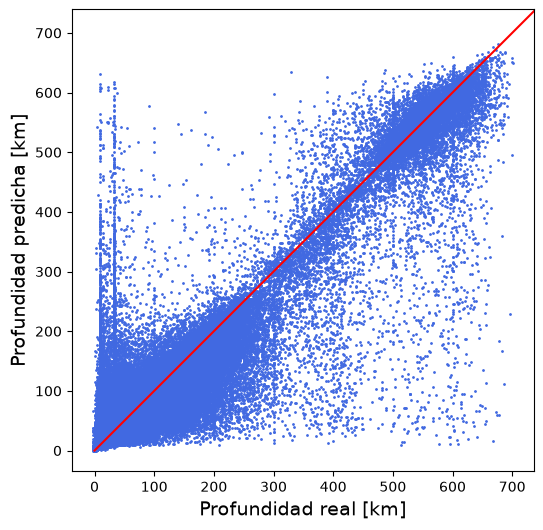

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(y2, ypred2, s = 1, c = 'royalblue')
plt.xlabel('Profundidad real [km]', fontsize=14)
plt.ylabel('Profundidad predicha [km]',fontsize=14)
plt.axis('square')
plt.plot([0,800], [0, 800], color='red')
plt.show()

Incluso después de haber eliminado los eventos de profundidad 0, notamos que hay dos "franjas" cerca de 0 que se mantienen. Al investigar, pudimos constatar que la usgs actualmente asigna 10 km cuando no se conoce la profundidad real del sismo, y 33 km en catálogos antiguos. Dado que las franjas son notorias haremos un chequeo de que fracción de la muestra total constituyen para evaluar su eliminación.

In [48]:
print((y2 == 10).mean(), (y2 == 33).mean())

0.24976696012428792 0.14819717762817194


Juntos, suman app el 38% de los datos totales. Esto es una gran fracción y conviene no considerarlos para evitar que el modelo intente aprender este rasgo. Es posible que haya cierta información real que se pierda al eliminar estos registros, pero creemos que conviene para mantener lo más limpia posible la muestra.

In [49]:
terremotos2 = terremotos2[~terremotos2["depth"].isin([10, 33])]

In [50]:
terremotos2.shape

(186005, 13)

Perdemos una gran cantidad de sismos al hacer este filtro. Sin embargo creemos que es lo mejor desde el punto de vista del aprendizaje del modelo.

In [51]:
X2 = terremotos2[features]
y2 = terremotos2[target]

Volvemos a evaluar $R^2$ y std, y a visualizar las profundidades reales y predichas en un gráfico.

In [52]:
%%time
cv = KFold(shuffle=True, n_splits=5, random_state=5)
scores = cross_validate(model, X2, y2, cv=cv, scoring='r2')

CPU times: total: 6min 18s
Wall time: 30 s


In [53]:
r2_prom = np.mean(scores['test_score'])
r2_std = np.std(scores['test_score'])
r2_prom, r2_std

(np.float64(0.9139130114521601), np.float64(0.0010832959355664452))

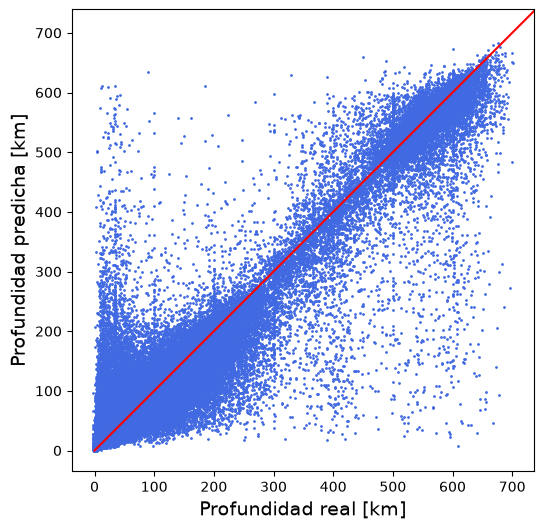

In [54]:
ypred2 = cross_val_predict(model, X2, y2, cv=cv)

plt.figure(figsize=(10,6))
plt.scatter(y2, ypred2, s = 1, c = 'royalblue')
plt.xlabel('Profundidad real [km]', fontsize=14)
plt.ylabel('Profundidad predicha [km]',fontsize=14)
plt.axis('square')
plt.plot([0,800], [0, 800], color='red')
plt.show()

Hemos logrado mejorar tanto $R^2$ ($\sim$ 0.91) como la desviación estándar ($\sim 0.001$). De momento ya tenemos un modelo bastante bueno. A continuación, haremos una separación entre conjunto de entrenamiento y conjunto de prueba.

## Separación entre entrenamiento y test

Hasta ahora obtuvimos el resultado del Random Forest mediante validación cruzada de 5 folds. Ahora separaremos un conjunto de entrenamiento y otro de test (seguimos utilizando X2, y2, model y las variables que ya definimos en las celdas anteriores).

Como la profundidad es una cantidad numérica (en km), estamos realizando una regresion. Elegimos Random Forest (un metodo de bagging basado en varios arboles de decisión), porque nos va a permitir modelar relaciones no lineales entre la profundidad, magnitud, ubicación y año.

Para definir los conjuntos, decidimos usar el 80% de los datos para entrenamiento y 20% para test, y conservaremos esta división durante el experimento.

In [55]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X_train, X_test, y_train, y_test = train_test_split(
    X2, y2, test_size=0.2, random_state=5
)

# Copia del modelo
modelo_original = clone(model)
modelo_original.set_params(random_state=5)
modelo_original.fit(X_train, y_train)

print("Cantidad de datos de entrenamiento:", len(X_train))
print("Cantidad de datos de test:", len(X_test))

Cantidad de datos de entrenamiento: 148804
Cantidad de datos de test: 37201


Ahora evaluaremos el modelo, mediante R^2, MAE y RMS, ya que R^2 es nuestro coeficiente de determinación, MAE representa el error promedio en kilometros y el RMSE penaliza los errores más grandes.


In [56]:
def evaluar(modelo, X_eval, y_eval):
    pred = modelo.predict(X_eval)
    return {
        "R2": r2_score(y_eval, pred),
        "MAE (km)": mean_absolute_error(y_eval, pred),
        "RMSE (km)": np.sqrt(mean_squared_error(y_eval, pred))
    }

resultados_original = pd.DataFrame({
    "Entrenamiento": evaluar(modelo_original, X_train, y_train),
    "Test": evaluar(modelo_original, X_test, y_test)
}).T

display(resultados_original.round(3))

,R2,MAE (km),RMSE (km)
Entrenamiento,0.988,7.645,15.203
Test,0.916,20.669,40.435


El modelo tiene un $R^2$ aprox de 0,988 en entrenamiento y 0,916 en test. Mientras que el MAE aumenta de 7645 km a 20669 km, lo cual nos indica que el desempeño del modelo baja considerablemente en los datos que no utilizó en el entrenamiento y sugiere un sobreajuste.
El resultado de $R^2$ es similar al que encontramos antes en la validación cruzada. De todas maneras, los 20669 km representan solo un promedio y para evaluar si es realmente confiable debemos identificar los errores grandes y revisar si se concentran en algun tipo de sismo.

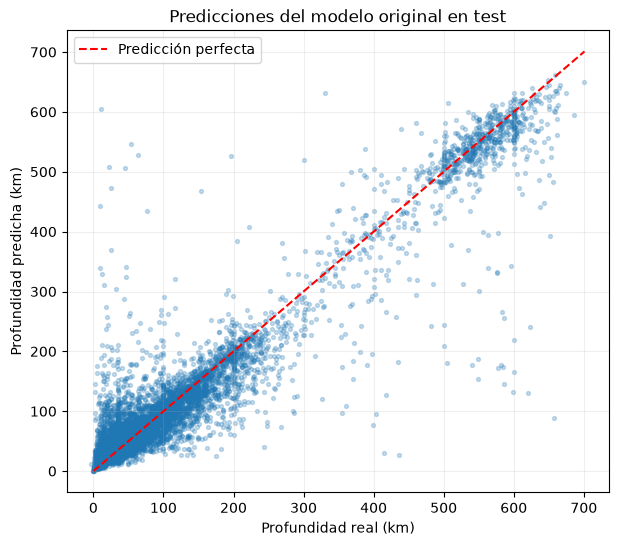

In [58]:
# Profundidad real versus predicha, ahora solo para los datos de test.
y_pred_test = modelo_original.predict(X_test)
comparacion_test = pd.DataFrame({"Real": y_test, "Predicha": y_pred_test})
muestra_test = comparacion_test.sample(n=min(10000, len(comparacion_test)), random_state=5)

plt.figure(figsize=(7, 6))
plt.scatter(muestra_test["Real"], muestra_test["Predicha"], s=8, alpha=0.25)
limite = max(comparacion_test["Real"].max(), comparacion_test["Predicha"].max())
plt.plot([0, limite], [0, limite], "r--", label="Predicción perfecta")
plt.xlabel("Profundidad real (km)")
plt.ylabel("Profundidad predicha (km)")
plt.title("Predicciones del modelo original en test")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Experimento: Modificación de un aspecto de la configuración

Ahora realizaremos un experimento donde veremos como cambia el comportamiento del modelo al modificar unicamente un aspecto de su configuración.

Modificaremos solo el hiperparámtro `max_depth`. Pensamos que al limitar el crecimiento de los árboles, disminuiremos la diferencia entre los conjuntos, ya que el modelo aprenderá reglas menos específicas de los datos de entrenamiento. Aunque, es posible también que la predicción en test empeore si es demasiado restrictiva.

Antes de definir un valor límite de profundidad para los árboles, veremos cual es la profundidad en promedio que están alcanzando con `max_depth=None`, y en base a eso definiremos el límite.

In [34]:
profundidades = [arbol.get_depth() for arbol in modelo_original.estimators_]
hojas = [arbol.get_n_leaves() for arbol in modelo_original.estimators_]

print("Profundidad de los árboles (max_depth=None):")
print(f"  mínima: {np.min(profundidades)}")
print(f"  media:  {np.mean(profundidades):.1f}")
print(f"  máxima: {np.max(profundidades)}")
print(f"Número medio de hojas: {np.mean(hojas):.0f}")

Profundidad de los árboles (max_depth=None):
  mínima: 43
  media:  46.8
  máxima: 53
Número medio de hojas: 104466


Dado que el los árboles están alcanzando un promedio de 47 niveles de profundidad, y la profundidad mínima alcanzada es de 43, pondremos un límite de 20, para asegurarnos de limitar el crecimiento de todos los árboles notoriamente, sin ser demasiado restrictivos tampoco.

In [61]:
#Copia del modelo pero limitado
modelo_limitado = clone(modelo_original)
modelo_limitado.set_params(max_depth=20)
modelo_limitado.fit(X_train, y_train)

resultados_experimento = pd.DataFrame({
    "Original - entrenamiento": evaluar(modelo_original, X_train, y_train),
    "Original - test": evaluar(modelo_original, X_test, y_test),
    "Limitado - entrenamiento": evaluar(modelo_limitado, X_train, y_train),
    "Limitado - test": evaluar(modelo_limitado, X_test, y_test)
}).T

display(resultados_experimento.round(3))

,R2,MAE (km),RMSE (km)
Original - entrenamiento,0.988,7.645,15.203
Original - test,0.916,20.669,40.435
Limitado - entrenamiento,0.977,12.223,20.826
Limitado - test,0.915,20.965,40.620


El $R^2$ en entrenamiento baja de 0,988 a 0,977 y el de test baja de 0,916 a 0,915. La brecha entre amabos conjuntos se reduce un poco lo cual es bueno. Pero el desempeño, aunque poco, empeora. Tanto el MAE como el RMSE suben en el conjunto de test limitado, aunque no mucho.

Esto nos hizo confirmar que el reducir la complejidad no necesariamente hará que mejoren las predicciones. En nuestro caso, pareciera ser que limitar el modelo hace que se pierda un poco la capacidad de aprender relaciones útiles. Por esto, mantendremos el modelo original para estudiar sus errores, ya que obtuvo mejores resultados para test.

## Auditoria del modelo
1. ¿Qué tan bien generaliza el modelo?

Según lo que hemos visto hasta ahora podemos decir que el Random Forest original obtiene métricas mejores en entrenamiento que en el test, lo cual es  un indicio de sobreajuste parcial. Sin embargo aun conserva un R^2 cercano a 0,91 en test, lo que nos indica que captura patrones de los datos no vistos.
Por último, como los datos fueron divididos de manera aleatoria, no sabemos si este desempeño se mantendría con otro conjunto.

2. ¿Dónde falla el modelo?

In [62]:
# Tabla de los casos con errores más altos en test.
auditoria = X_test.copy()
auditoria["Profundidad real (km)"] = y_test
auditoria["Profundidad predicha (km)"] = y_pred_test
auditoria["Error absoluto (km)"] = (
    auditoria["Profundidad real (km)"] - auditoria["Profundidad predicha (km)"]
).abs()

print("Sismos con mayores errores del modelo:")
display(auditoria.nlargest(10, "Error absoluto (km)").round(2))

Sismos con mayores errores del modelo:


,mag,longitude,latitude,time,Profundidad real (km),Profundidad predicha (km),Error absoluto (km)
282165,4.90,-179.80,-21.69,2022,11.26,605.42,594.16
248719,4.70,179.68,-17.72,2018,22.46,609.97,587.51
17746,5.83,173.06,-18.16,1972,595.00,21.86,573.14
97904,4.60,142.37,23.97,1993,656.90,88.75,568.15
56885,4.70,171.04,-14.67,1984,26.70,583.30,556.60
253790,4.90,-63.19,-21.68,2019,20.57,563.58,543.01
139730,4.80,123.76,6.56,2003,41.40,580.63,539.23
88632,5.00,174.24,-39.14,1991,588.40,49.81,538.59
42374,5.00,-71.18,-6.09,1980,42.00,574.80,532.80
186245,4.60,159.42,-9.67,2010,548.70,34.35,514.35


,N_sismos,MAE_km,Mediana_km
Rango de profundidad,,,
Hasta 70 km,23546,14.92,7.82
70 a 300 km,10517,26.45,17.55
Más de 300km,3115,44.69,21.53


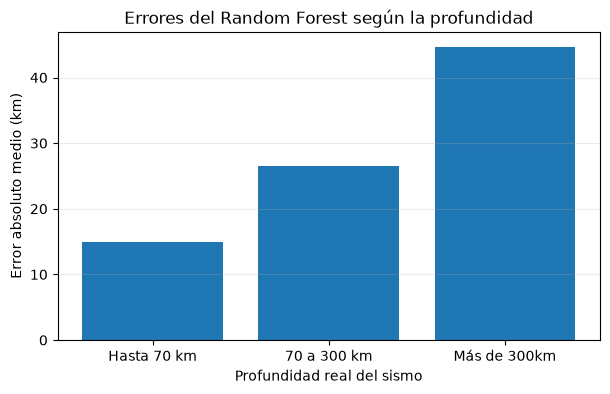

In [63]:
# ¿Cambian los errores según la profundidad del sismo?
auditoria["Rango de profundidad"] = pd.cut(
    auditoria["Profundidad real (km)"],
    bins=[0, 70, 300, np.inf],
    labels=["Hasta 70 km", "70 a 300 km", "Más de 300km"],
    include_lowest=True
)

resumen_errores = (
    auditoria.groupby("Rango de profundidad", observed=True)["Error absoluto (km)"]
    .agg(N_sismos="count", MAE_km="mean", Mediana_km="median")
)
display(resumen_errores.round(2))

plt.figure(figsize=(7, 4))
plt.bar(resumen_errores.index.astype(str), resumen_errores["MAE_km"])
plt.ylabel("Error absoluto medio (km)")
plt.xlabel("Profundidad real del sismo")
plt.title("Errores del Random Forest según la profundidad")
plt.grid(axis="y", alpha=0.25)
plt.show()

A partir de los ejemplos, se ven muchos casos donde en sismos de mas de 600km de profundidad se predicen valores muy bajos como de 88 km, y lo mismo en el caso inverso, donde hay sismos de muy poca profundidad donde se les asigna valores de 605 km por ejemplo.
Además, el MAE es de aprox. 14.92 km en sismos de hasta 70km, 26.45 km entre 70 y 300km, y 44.69 en sismos de mas de 300km.  Por lo que podemos concluir que el modelo presenta mayores discrepancias en sismos de gran profundidad.
Esto tambien podría deberse a que los sismos de gran profundidad son menos frecuentes en el conjunto de test, de acuerdo con lo que vimos en el análisis de la tarea 1, por lo que esto podría estar influyendo en el entrenamiento.

3. ¿Qué aprendieron que no era evidente a partir de una única métrica global?

Aprendimos que aunque el $R^2$ de test parecía bastante bueno en un principio, esto no refleja que algunos eventos pueden llegar a tener grandes errores, por lo que es necesario evaluar varias métricas para obtener un análisis más representativo. Descubrimos que los eventos con mayor profundidad presentan un MAE mayor y que el desempeño del modelo empeoró al disminuir la diferencia entre entrenamiento y test, reduciendo la profundidad de los arboles.

4. ¿Cómo mejorarían el modelo?

Una posible mejora sería incorporar información geográfica de las placas tectónicas o distancia del sismo a zonas de subducción de las placas. Esto podría darle un contexto físico al modelo que no se encuentra representado por completo por la latitud, longitud, magnitud o el año, que son las variables que utilizamos para este trabajo.

Esto es importante porque es probable que los sismos de gran profundidad sean los que se encuentran cercanos a la zona de subducción.

Para implementarlo tendríamos que obtener primero estos datos y luego evaluar nuevamente el modelo.

## Conclusiones

Consideramos que el modelo es moderadamente confiable, y su confiabilidad depende del tipo de sismo.

El Random Forest captura bien la relación entre la ubicación del sismo y su profundidad. Obtiene un $R^2$ $\sim$ 0.91 en test, con resultados muy estables entre folds de la validación cruzada (desviación estándar ≈ 0,001). Para sismos cd hasta 70 km, que son la gran mayoría, el error típico es bajo, con una mediana del error absoluto de $\sim$ 7.82

Sim embargo hay limitaciones. El desempeño empeora mucho en sismos profundos. Sobre 300 km el MAE llega a $\sim$ 44 km y hay errores de más de 500 km en ambas direcciones. El experimento mostró que limitar la profundidad de los árboles reduce la brecha asociada al sobreajuste, pero también empeora el desempeño general en test, aunque no demasidao. Por último, como la separación entre entrenamiento y test fue aleatoria y los sismos ocurren agrupados en el espacio y el tiempo, es posible que con otros subconjuntos los resultados no sean los mismos. 

En conclusión, el modelo podría servir como estimación aproximada de la profundidad en registros históricos incompletos, principalmente para sismos que se supongan de baja profundidad. No sería adecuado para aplicaciones que requieran precisión en sismos profundos o en zonas con pocos registros. Este caso muestra que una buena métrica global no garantiza un buen desempeño en todos los casos, y que es necesario analizar los errores por subgrupos.

#### Uso de IA
Nota: En esta tarea se usó IA en forma moderada, solo como apoyo para ALGUNOS de los fragmentos de código.